In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from pathlib import Path
import pandas as pd
import sys
sys.path.append("..")

PROJECT_ROOT = Path.cwd().resolve().parent   
sys.path.insert(0, str(PROJECT_ROOT)) 

from src.trainer.eval_baselines import evaluate_baselines
from src.trainer.evaluate import evaluate_basics_models
from src.visualization.model_perf_plots import plot_mae_vs_k, plot_mae_vs_k_extra_features
from src.trainer.cross_validate import run_cross_validation

### Baseline Models

In [3]:
evaluate_baselines()


=== VALIDATION BASELINE RESULTS (CGM ONLY) ===
 k_days target       model      MAE     RMSE      Bias
      1 y_mean    Constant 0.459332 0.599154 -0.001417
      1 y_mean Persistence 0.239647 0.306065 -0.053975
      1   y_cv    Constant 2.900507 3.666716 -0.113078
      1   y_cv Persistence 2.959964 3.771641 -0.019201
      3 y_mean    Constant 0.459332 0.599154 -0.001417
      3 y_mean Persistence 0.234139 0.298013 -0.074329
      3   y_cv    Constant 2.900507 3.666716 -0.113078
      3   y_cv Persistence 2.884855 3.832371  1.946703
      5 y_mean    Constant 0.459332 0.599154 -0.001417
      5 y_mean Persistence 0.250325 0.314592 -0.104782
      5   y_cv    Constant 2.900507 3.666716 -0.113078
      5   y_cv Persistence 2.986205 3.779581  1.949919
      7 y_mean    Constant 0.459332 0.599154 -0.001417
      7 y_mean Persistence 0.262174 0.333759 -0.093165
      7   y_cv    Constant 2.900507 3.666716 -0.113078
      7   y_cv Persistence 3.020419 3.790738  2.244483

Saved results ->

,k_days,target,model,MAE,RMSE,Bias
0,1,y_mean,Constant,0.459332,0.599154,-0.001417
1,1,y_mean,Persistence,0.239647,0.306065,-0.053975
2,1,y_cv,Constant,2.900507,3.666716,-0.113078
3,1,y_cv,Persistence,2.959964,3.771641,-0.019201
4,3,y_mean,Constant,0.459332,0.599154,-0.001417
5,3,y_mean,Persistence,0.234139,0.298013,-0.074329
6,3,y_cv,Constant,2.900507,3.666716,-0.113078
7,3,y_cv,Persistence,2.884855,3.832371,1.946703
8,5,y_mean,Constant,0.459332,0.599154,-0.001417
9,5,y_mean,Persistence,0.250325,0.314592,-0.104782


Ridge Regression, Random forest and Gradient boosting

In [ ]:
evaluate_basics_models ()

 k_days   features target            model    MAE   RMSE    bias  MAE_train
      1       base y_mean            Ridge 0.2247 0.2945  0.0183     0.2055
      1       base y_mean     RandomForest 0.2380 0.3028 -0.0085     0.1419
      1       base y_mean GradientBoosting 0.2328 0.3025  0.0017     0.1236
      1       base   y_cv            Ridge 2.0457 2.6881 -0.3282     2.2333
      1       base   y_cv     RandomForest 2.2314 2.9133 -0.3863     1.5785
      1       base   y_cv GradientBoosting 2.3078 3.0841 -0.2494     1.4493
      1 base+extra y_mean            Ridge 0.2276 0.3010  0.0220     0.2028
      1 base+extra y_mean     RandomForest 0.2350 0.3051 -0.0053     0.1353
      1 base+extra y_mean GradientBoosting 0.2298 0.3006  0.0022     0.1169
      1 base+extra   y_cv            Ridge 2.0513 2.6814 -0.2788     2.2249
      1 base+extra   y_cv     RandomForest 2.2150 2.9027 -0.3545     1.5522
      1 base+extra   y_cv GradientBoosting 2.3293 3.0918 -0.1272     1.3996
      3     

,k_days,features,target,model,MAE,RMSE,bias,MAE_train
0,1,base,y_mean,Ridge,0.2247,0.2945,0.0183,0.2055
1,1,base,y_mean,RandomForest,0.2380,0.3028,-0.0085,0.1419
2,1,base,y_mean,GradientBoosting,0.2328,0.3025,0.0017,0.1236
3,1,base,y_cv,Ridge,2.0457,2.6881,-0.3282,2.2333
4,1,base,y_cv,RandomForest,2.2314,2.9133,-0.3863,1.5785
5,1,base,y_cv,GradientBoosting,2.3078,3.0841,-0.2494,1.4493
6,1,base+extra,y_mean,Ridge,0.2276,0.3010,0.0220,0.2028
7,1,base+extra,y_mean,RandomForest,0.2350,0.3051,-0.0053,0.1353
8,1,base+extra,y_mean,GradientBoosting,0.2298,0.3006,0.0022,0.1169
9,1,base+extra,y_cv,Ridge,2.0513,2.6814,-0.2788,2.2249


### Model and durations comparisation

In [4]:
results_dir = Path.cwd().parents[1] / "results"
df_val = pd.read_csv(results_dir / "models_val_results.csv")
df_baselines = pd.read_csv(results_dir / "baseline_val_results.csv")

mean glucose

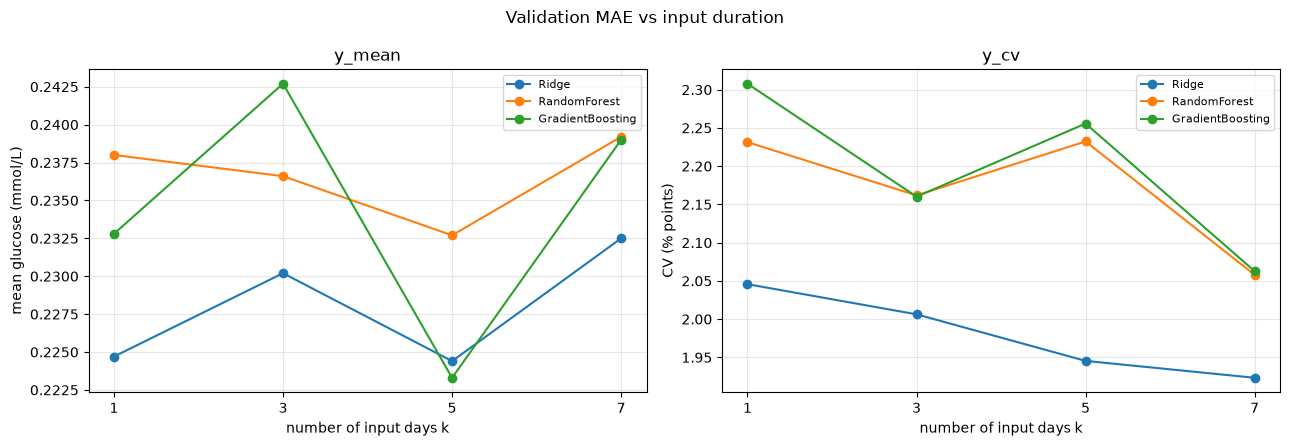

In [4]:
plot_mae_vs_k(df_val)

extra feature comparison

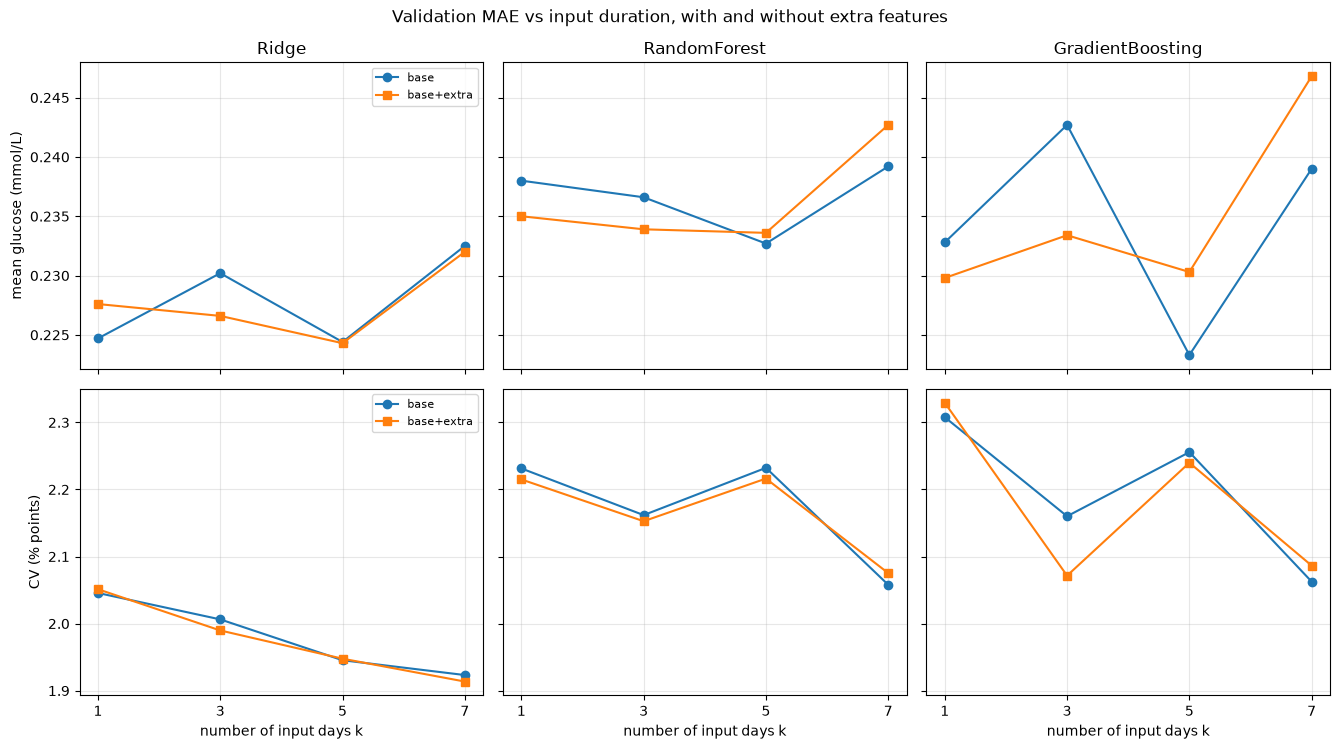

In [5]:
plot_mae_vs_k_extra_features(df_val)

## Cross validation

In [ ]:
run_cross_validation()
df_cv = pd.read_csv(results_dir / "models_cv_results.csv")

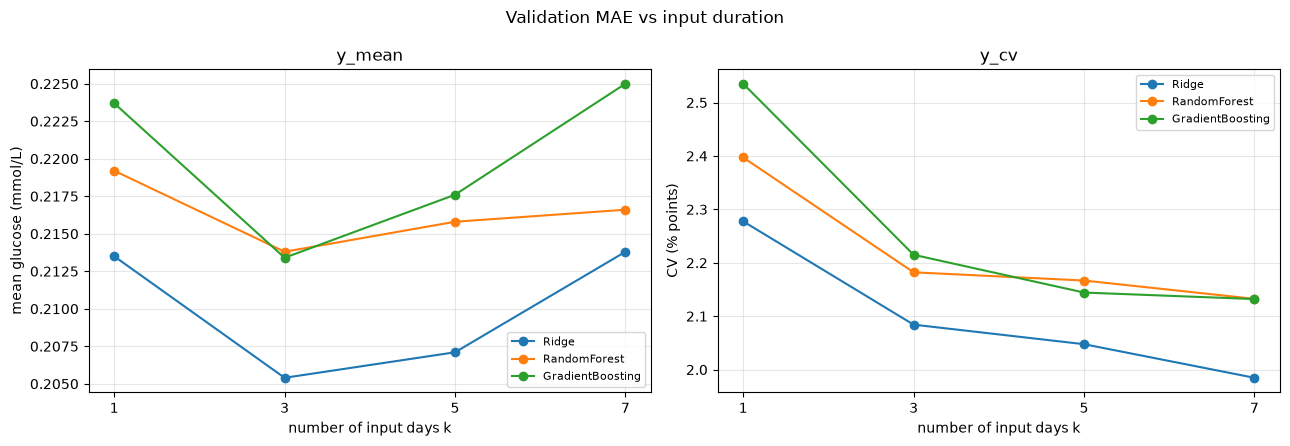

In [6]:
plot_mae_vs_k (df_cv)